# Chapter 6: Outliers and Data Quality Checks

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 6.1 Wrong, or Just Unusual?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('book.mplstyle')

orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
tickets = pd.read_csv('support_tickets.csv',
                      parse_dates=['opened_date'])
add_ons = orders[orders['order_type'] == 'Add-on'].copy()
add_ons[['order_date', 'items', 'amount', 'delivery_days']].head()

,order_date,items,amount,delivery_days
22,2024-01-08,1,18.47,2
23,2024-01-08,1,11.19,2
48,2024-01-16,1,16.02,2
67,2024-01-19,1,16.96,2
76,2024-01-21,2,20.65,5


## 6.2 The IQR Rule

In [2]:
def iqr_fences(values, k=1.5):
    q1, q3 = values.quantile([0.25, 0.75])
    spread = q3 - q1
    return q1 - k * spread, q3 + k * spread

low, high = iqr_fences(add_ons['amount'])
print(f'Fences: {low:.2f} to {high:.2f}')

Fences: -11.10 to 55.00


In [3]:
outside = add_ons[(add_ons['amount'] < low)
                  | (add_ons['amount'] > high)]
print(f'Flagged: {len(outside)} of {len(add_ons)}')
print(f"Share: {len(outside) / len(add_ons):.1%}")

Flagged: 212 of 4520
Share: 4.7%


In [4]:
far_low, far_high = iqr_fences(add_ons['amount'], k=3)
far_out = add_ons[add_ons['amount'] > far_high]
print(f'Far-out fence: {far_high:.2f}')
print(f'Far-out orders: {len(far_out)}')

Far-out fence: 79.79
Far-out orders: 45


In [5]:
far_out.sort_values('amount', ascending=False)[
    ['order_date', 'items', 'amount']].head(6)

,order_date,items,amount
9144,2025-01-20,25,635.74
23411,2025-10-22,15,630.63
18022,2025-07-22,11,619.16
18208,2025-07-25,19,580.08
26361,2025-12-03,16,579.63
27480,2025-12-16,24,569.42


In [6]:
gift_like = far_out['items'] >= 10
print(f'Orders of 10 or more bags: {gift_like.sum()}')
print(far_out.loc[~gift_like, ['items', 'amount']].agg(['min', 'max']))

Orders of 10 or more bags: 24
     items  amount
min      2   80.23
max      3  127.25


### The same rule on other columns

In [7]:
def count_outside(values, k=1.5):
    low, high = iqr_fences(values, k)
    return ((values < low) | (values > high)).sum()

columns = {
    'add-on amount': add_ons['amount'],
    'delivery days': orders['delivery_days'],
    'hours to resolve': tickets['hours_to_resolve'],
}
rows = []
for name, values in columns.items():
    rows.append({'column': name, 'rows': len(values),
                 'beyond 1.5': count_outside(values),
                 'beyond 3': count_outside(values, k=3)})
flag_counts = pd.DataFrame(rows).set_index('column')
flag_counts

,rows,beyond 1.5,beyond 3
column,,,
add-on amount,4520,212,45
delivery days,28772,360,5
hours to resolve,1380,105,41


In [8]:
for name in ['delivery days', 'hours to resolve']:
    fence_low, fence_high = iqr_fences(columns[name])
    far_fence = iqr_fences(columns[name], k=3)[1]
    print(f'{name}: {fence_low:.1f} to {fence_high:.1f}, '
          f'far-out above {far_fence:.1f}')

delivery days: -1.0 to 7.0, far-out above 10.0
hours to resolve: -9.0 to 23.5, far-out above 35.6


## 6.3 z-Scores

### `stats.zscore()`

In [9]:
amount_z = stats.zscore(add_ons['amount'])
print(f'Lowest z:  {amount_z.min():.2f}')
print(f'Highest z: {amount_z.max():.2f}')
print(f'Orders beyond 3: {(np.abs(amount_z) > 3).sum()}')

Lowest z:  -0.61
Highest z: 17.59
Orders beyond 3: 24


In [10]:
regular = add_ons[add_ons['items'] < 10].copy()
print(f"Std with gift orders:    {add_ons['amount'].std():.2f}")
print(f"Std without gift orders: {regular['amount'].std():.2f}")

Std with gift orders:    34.68
Std without gift orders: 14.27


In [11]:
add_ons['z_all'] = stats.zscore(add_ons['amount'])
regular['z_regular'] = stats.zscore(regular['amount'])

biggest = regular['amount'].idxmax()
z_in = add_ons.loc[biggest, 'z_all']
z_out = regular.loc[biggest, 'z_regular']
print(f'z with the gift orders in:  {z_in:.2f}')
print(f'z with the gift orders out: {z_out:.2f}')

z with the gift orders in:  2.93
z with the gift orders out: 7.26


In [12]:
ages = customers['age'].dropna()
age_z = stats.zscore(ages)
print(f'Ages beyond 3: {(np.abs(age_z) > 3).sum()}')
print(f'Oldest customer: {ages.max():.0f}, z = {age_z.max():.2f}')

Ages beyond 3: 3
Oldest customer: 76, z = 3.52


In [13]:
flag_counts['z beyond 3'] = [
    (np.abs(stats.zscore(values)) > 3).sum()
    for values in columns.values()
]
flag_counts

,rows,beyond 1.5,beyond 3,z beyond 3
column,,,,
add-on amount,4520,212,45,24
delivery days,28772,360,5,102
hours to resolve,1380,105,41,29


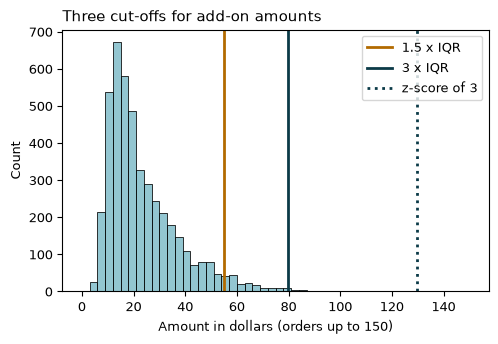

In [14]:
amount_cut = (add_ons['amount'].mean()
              + 3 * add_ons['amount'].std())

ax = sns.histplot(data=add_ons, x='amount', binrange=(0, 150),
                  binwidth=3, color='#6fb3c2')
ax.axvline(high, color='#b26a00', label='1.5 x IQR')
ax.axvline(far_high, color='#0b3a47', label='3 x IQR')
ax.axvline(amount_cut, color='#0b3a47', linestyle=':',
           label='z-score of 3')
ax.legend()
ax.set_title('Three cut-offs for add-on amounts')
ax.set_xlabel('Amount in dollars (orders up to 150)')
plt.show()

## 6.4 Error or Real? Deciding What to Do

In [15]:
checks = {
    'amount of $0 or less': (orders['amount'] <= 0).sum(),
    'delivery in under 1 day': (orders['delivery_days'] < 1).sum(),
    'age under 18 or over 100': ((customers['age'] < 18)
                                 | (customers['age'] > 100)).sum(),
    'ticket closed in 0 hours or less': (
        tickets['hours_to_resolve'] <= 0).sum(),
}
pd.Series(checks)

amount of $0 or less                0
delivery in under 1 day             0
age under 18 or over 100            0
ticket closed in 0 hours or less    0
dtype: int64

In [16]:
gift_orders = add_ons[add_ons['items'] >= 10]
gift_orders[['items', 'amount']].agg(['min', 'max'])

,items,amount
min,10,194.62
max,28,635.74


In [17]:
summary = pd.DataFrame({
    'all orders': add_ons['amount'].agg(['count', 'mean', 'median']),
    'without gift orders': regular['amount'].agg(['count', 'mean',
                                                   'median']),
}).round(2)
summary

,all orders,without gift orders
count,4520.00,4496.00
mean,25.82,23.64
median,19.26,19.19


In [18]:
gift_revenue = add_ons.loc[add_ons['items'] >= 10, 'amount'].sum()
print(f"Gift orders: {(add_ons['items'] >= 10).mean():.1%} of orders")
print(f"Gift revenue: {gift_revenue / add_ons['amount'].sum():.1%}")

Gift orders: 0.5% of orders
Gift revenue: 8.9%


## 6.5 Missing Values

### `df.isna().mean()`

In [19]:
customers.isna().mean().round(3)

customer_id    0.00
signup_date    0.00
city           0.00
state          0.00
region         0.00
age            0.04
channel        0.00
plan           0.00
device         0.00
dtype: float64

In [20]:
ab_test = pd.read_csv('ab_test.csv', parse_dates=['visit_date'])
tables = {'customers': customers, 'orders': orders,
          'tickets': tickets, 'ab_test': ab_test}

for name, table in tables.items():
    share = table.isna().mean()
    print(f'{name}: {share[share > 0].round(3).to_dict()}')

customers: {'age': 0.04}
orders: {}
tickets: {}
ab_test: {'order_value': 0.913}


### Do the blanks follow a pattern?

In [21]:
customers['age_missing'] = customers['age'].isna()
by_channel = customers.groupby('channel')['age_missing'].agg(
    ['sum', 'mean'])
by_channel.sort_values('mean', ascending=False).round(3)

,sum,mean
channel,,
Social,102,0.096
Email,17,0.038
Search,29,0.020
Referral,9,0.016
Podcast,10,0.015


In [22]:
cancels = pd.read_csv('cancellations.csv',
                      parse_dates=['cancel_date'])
customers['cancelled'] = customers['customer_id'].isin(
    cancels['customer_id'])

print(customers.groupby('plan')['age_missing'].mean().round(3))
print(customers.groupby('age_missing')['cancelled'].mean().round(3))

plan
Basic       0.039
Premium     0.041
Standard    0.040
Name: age_missing, dtype: float64
age_missing
False    0.563
True     0.557
Name: cancelled, dtype: float64


In [23]:
customers.groupby('channel')['age'].mean().round(1)

channel
Email       38.7
Podcast     37.5
Referral    38.2
Search      37.9
Social      37.9
Name: age, dtype: float64

### What a blank means

In [24]:
ab_test['order_missing'] = ab_test['order_value'].isna()
ab_test.groupby('purchased')['order_missing'].mean()

purchased
0    1.0
1    0.0
Name: order_missing, dtype: float64

In [25]:
buyers = ab_test['purchased'].sum()
print(f'Visitors who bought: {buyers} ({buyers / len(ab_test):.1%})')
print(f"Mean order value: ${ab_test['order_value'].mean():.2f}")

Visitors who bought: 1975 (8.7%)
Mean order value: $32.26


### `s.fillna()`

In [26]:
value_per_visitor = ab_test['order_value'].fillna(0)
print(f'Average per visitor: ${value_per_visitor.mean():.2f}')

Average per visitor: $2.80


In [27]:
filled = customers['age'].fillna(customers['age'].median())
print(f"Std of age, blanks left out: {customers['age'].std():.2f}")
print(f"Std of age, filled with 38:  {filled.std():.2f}")

Std of age, blanks left out: 10.81
Std of age, filled with 38:  10.60


## 6.6 Duplicates

### `df.duplicated()`

In [28]:
print(f'Repeated order rows:    {orders.duplicated().sum()}')
print(f'Repeated customer rows: {customers.duplicated().sum()}')

Repeated order rows:    0
Repeated customer rows: 0


In [29]:
print(f"Repeated order_id:    {orders['order_id'].duplicated().sum()}")
print(f"Repeated customer_id: "
      f"{customers['customer_id'].duplicated().sum()}")

Repeated order_id:    0
Repeated customer_id: 0


In [30]:
same_day = orders.duplicated(
    subset=['customer_id', 'order_date', 'order_type'])
print(f'Same customer, day and type: {same_day.sum()}')

Same customer, day and type: 0


In [31]:
export = pd.DataFrame({
    'customer_id': [1001, 1002, 1003, 1002, 1004, 1003],
    'name': ['Ana Lopez', 'Ben Carter', 'Cara Singh', 'Ben Carter',
             'Dev Patel', 'Cara Singh'],
    'plan': ['Basic', 'Standard', 'Premium', 'Standard', 'Basic',
             'Standard'],
})
export

,customer_id,name,plan
0,1001,Ana Lopez,Basic
1,1002,Ben Carter,Standard
2,1003,Cara Singh,Premium
3,1002,Ben Carter,Standard
4,1004,Dev Patel,Basic
5,1003,Cara Singh,Standard


In [32]:
export.duplicated()

0    False
1    False
2    False
3     True
4    False
5    False
dtype: bool

In [33]:
export.duplicated(subset='customer_id')

0    False
1    False
2    False
3     True
4    False
5     True
dtype: bool

In [34]:
export[export.duplicated(subset='customer_id', keep=False)]

,customer_id,name,plan
1,1002,Ben Carter,Standard
2,1003,Cara Singh,Premium
3,1002,Ben Carter,Standard
5,1003,Cara Singh,Standard


### `df.drop_duplicates()`

In [35]:
clean = export.drop_duplicates()
print(f'Rows before: {len(export)}, after: {len(clean)}')

Rows before: 6, after: 5


## 6.7 Binning Numbers into Groups

### `pd.cut()`

In [36]:
age_edges = [18, 25, 35, 45, 55, 65, 120]
age_groups = pd.cut(customers['age'], bins=age_edges)
print(age_groups.isna().sum())

338


In [37]:
age_labels = ['18-24', '25-34', '35-44', '45-54', '55-64', '65+']
customers['age_group'] = pd.cut(customers['age'], bins=age_edges,
                                right=False, labels=age_labels)
customers['age_group'].value_counts(dropna=False).sort_index()

age_group
18-24     473
25-34    1080
35-44    1386
45-54     813
55-64     259
65+        32
NaN       167
Name: count, dtype: int64

In [38]:
by_age = customers.groupby('age_group')['cancelled'].agg(
    ['count', 'mean'])
by_age.round(3)

,count,mean
age_group,,
18-24,473,0.645
25-34,1080,0.601
35-44,1386,0.541
45-54,813,0.528
55-64,259,0.506
65+,32,0.375


### `pd.qcut()`

In [39]:
spend = orders.groupby('customer_id')['amount'].sum()
pd.cut(spend, bins=4).value_counts().sort_index()

amount
(6.481, 387.795]       3574
(387.795, 767.59]       499
(767.59, 1147.385]      109
(1147.385, 1527.18]      28
Name: count, dtype: int64

In [40]:
spend_labels = ['Lowest', 'Lower-mid', 'Upper-mid', 'Highest']
spend_group = pd.qcut(spend, q=4, labels=spend_labels)
spend_group.value_counts().sort_index()

amount
Lowest       1053
Lower-mid    1052
Upper-mid    1052
Highest      1053
Name: count, dtype: int64

In [41]:
by_group = spend.groupby(spend_group)
summary = pd.DataFrame({
    'lowest $': by_group.min(),
    'highest $': by_group.max(),
    'share of revenue': by_group.sum() / spend.sum(),
}).round(3)
summary

,lowest $,highest $,share of revenue
amount,,,
Lowest,8.00,24.56,0.020
Lower-mid,24.59,95.31,0.079
Upper-mid,95.40,249.59,0.215
Highest,249.62,1527.18,0.686
